In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import (LinearRegression, Ridge, Lasso,
                                  RidgeCV, LassoCV, lasso_path)
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import mean_squared_error
from sklearn.datasets import load_diabetes, load_breast_cancer, make_friedman1
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neural_network import MLPRegressor

RS = 4

plt.rcParams.update({
    "figure.figsize": (9, 3.6),
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 10,
    "legend.framealpha": 0.9,
})

def rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))


print("numpy", np.__version__, "| pandas", pd.__version__, "| sklearn", sklearn.__version__)

numpy 2.1.1 | pandas 2.2.3 | sklearn 1.6.1


---
Зависимость `f(x) = sin(2πx)`, но берём только 12 точек + шум. Учим полином 15 степени

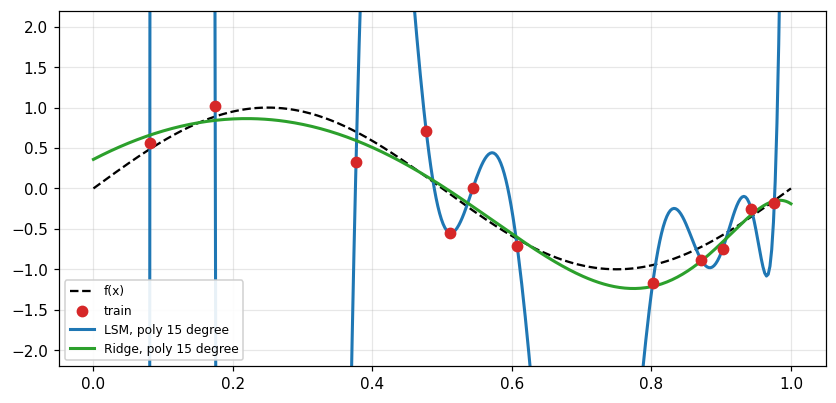

        Model  RMSE train  RMSE test
          LSM      0.0000   980.1080
Ridge, λ=1e-3      0.2516     0.2837

Sum |coef|: LSM = 392197715.1, Ridge = 10.2


In [2]:
def true_f(x):
    return np.sin(2 * np.pi * x)


def make_sine_data(n, noise=0.25, seed=RS):
    r = np.random.default_rng(seed)
    x = np.sort(r.uniform(0, 1, n))
    return x.reshape(-1, 1), true_f(x) + r.normal(0, noise, n)


X_tr, y_tr = make_sine_data(12, seed=RS)
X_te, y_te = make_sine_data(400, seed=RS + 1)
grid = np.linspace(0, 1, 400).reshape(-1, 1)

DEG = 15
lsm = make_pipeline(PolynomialFeatures(DEG), LinearRegression()).fit(X_tr, y_tr)
rdg = make_pipeline(PolynomialFeatures(DEG), StandardScaler(), Ridge(alpha=1e-3)).fit(X_tr, y_tr)

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(grid, true_f(grid.ravel()), "k--", lw=1.5, label="f(x)")
ax.scatter(X_tr, y_tr, s=45, zorder=5, color="#d62728", label="train")
ax.plot(grid, lsm.predict(grid), lw=2, color="#1f77b4", label=f"LSM, poly {DEG} degree")
ax.plot(grid, rdg.predict(grid), lw=2, color="#2ca02c", label=f"Ridge, poly {DEG} degree")
ax.set_ylim(-2.2, 2.2)
ax.legend(loc="lower left", fontsize=8)
plt.show()

print(pd.DataFrame({
    "Model": ["LSM", "Ridge, λ=1e-3"],
    "RMSE train": [rmse(y_tr, lsm.predict(X_tr)), rmse(y_tr, rdg.predict(X_tr))],
    "RMSE test": [rmse(y_te, lsm.predict(X_te)), rmse(y_te, rdg.predict(X_te))],
}).round(4).to_string(index=False))
print("\nSum |coef|: LSM = {:.1f}, Ridge = {:.1f}".format(
    np.abs(lsm[-1].coef_).sum(), np.abs(rdg[-1].coef_).sum()))

### Analytical solution

5 точек, 2 почти равные фичи  (`x2 ≈ x1`), зависимость `y = x1 + x2` + eps (±0.03).

In [8]:
x1 = np.array([1., 2., 3., 4., 5.])
x2 = x1 + np.array([0.01, -0.01, 0.00, 0.01, -0.01])
Xm = np.column_stack([x1, x2])
noise = np.array([0.02, -0.03, 0.01, 0.03, -0.02])
ym = 1.0 * x1 + 1.0 * x2 + noise

XtX = Xm.T @ Xm
print("XᵀX =\n", np.round(XtX, 3))
print("\ndet(XᵀX) = {:.6f}".format(np.linalg.det(XtX)))
print("\tcondition number = {:.2e}".format(np.linalg.cond(XtX)))

w_ols = np.linalg.solve(XtX, Xm.T @ ym)
print("\nLSM w = [{:+.3f}, {:+.3f}], |w| = {:.2f}".format(
    w_ols[0], w_ols[1], np.abs(w_ols).sum()))
print("\tRMSE train: {:.4f}".format(
    rmse(ym, Xm @ w_ols)))

rows = []
for lam in [0.0, 0.01, 0.1, 1.0, 10.0]:
    w = np.linalg.solve(XtX + lam * np.eye(2), Xm.T @ ym)
    rows.append({"λ": lam, "w1": w[0], "w2": w[1],
                 "sum |w|": np.abs(w).sum(), "RMSE train": rmse(ym, Xm @ w)})
print("\nRidge: (XᵀX + λI)·w = Xᵀy")
print(pd.DataFrame(rows).round(4).to_string(index=False))

XᵀX =
 [[55.   54.98]
 [54.98 54.96]]

det(XᵀX) = 0.021600
	condition number = 5.60e+05

LSM w = [-1.554, +3.556], |w| = 5.11
	RMSE train: 0.0052

Ridge: (XᵀX + λI)·w = Xᵀy
    λ      w1     w2  sum |w|  RMSE train
 0.00 -1.5544 3.5556   5.1100      0.0052
 0.01  0.9510 1.0491   2.0000      0.0228
 0.10  0.9944 1.0040   1.9984      0.0240
 1.00  0.9908 0.9914   1.9822      0.0641
10.00  0.9168 0.9166   1.8335      0.5534


### L1 feature selection

Lasso: `min ‖y − Xw‖² + λ‖w‖₁`.

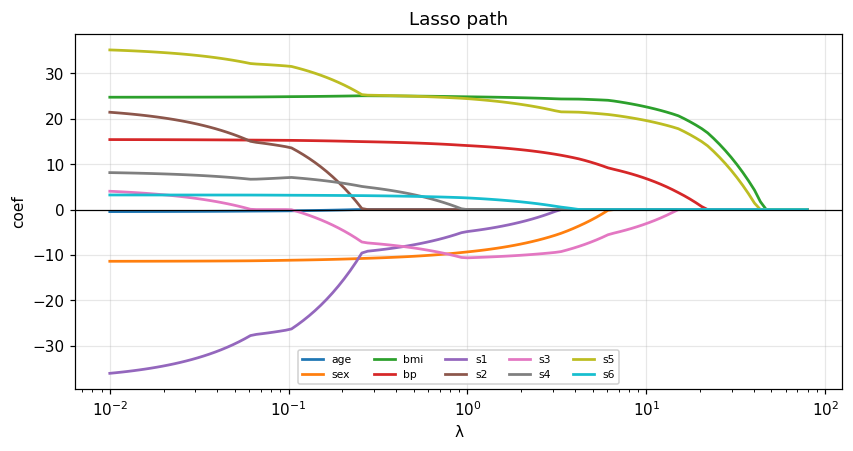

    λ  non-zero                        surviving features
 0.01        10 age, sex, bmi, bp, s1, s2, s3, s4, s5, s6
 0.50         8          sex, bmi, bp, s1, s3, s4, s5, s6
 2.00         7              sex, bmi, bp, s1, s3, s5, s6
 5.00         5                      sex, bmi, bp, s3, s5
20.00         3                               bmi, bp, s5


In [4]:
dia = load_diabetes()
Xd = StandardScaler().fit_transform(dia.data)
yd = dia.target
names = list(dia.feature_names)

alphas_l, coefs_l, _ = lasso_path(Xd, yd, alphas=np.logspace(1.9, -2, 120))

fig, ax = plt.subplots(figsize=(9, 4.2))
for i, nm in enumerate(names):
    ax.semilogx(alphas_l, coefs_l[i], lw=1.8, label=nm)
ax.axhline(0, color="k", lw=0.8)
ax.set_xlabel("λ")
ax.set_ylabel("coef")
ax.set_title("Lasso path")
ax.legend(ncol=5, fontsize=7, loc="lower center")
plt.show()

rows = []
for a in [0.01, 0.5, 2.0, 5.0, 20.0]:
    las = Lasso(alpha=a, max_iter=50000).fit(Xd, yd)
    alive = [n for n, c in zip(names, las.coef_) if abs(c) > 1e-8]
    rows.append({"λ": a, "non-zero": len(alive), "surviving features": ", ".join(alive) or "—"})
print(pd.DataFrame(rows).to_string(index=False))

### Cost-complexity pruning

Post-pruning минимизирует

$$R_\alpha(T) = R(T) + \alpha\,|T|$$

Data: `breast_cancer` (569 samples, 30 фич + 30 шумных фич).
`α` по кросс валидации на трейне.

Features: 60 (30 + 30 noise)


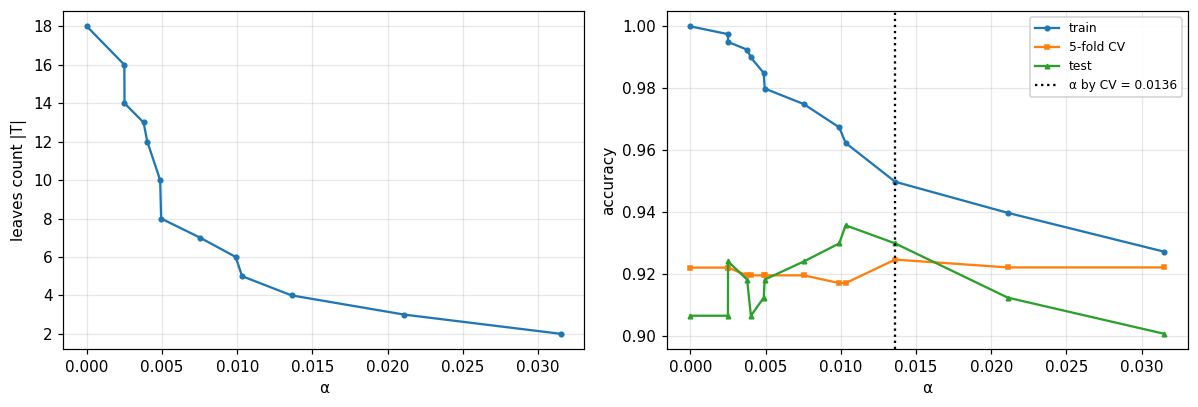

Full tree:  leaves  18, train acc 1.000, test acc 0.906
Pruned:     leaves   4, train acc 0.950, test acc 0.930  (α = 0.0136)


In [9]:
bc = load_breast_cancer()
noise_cols = np.random.default_rng(0).normal(size=(bc.data.shape[0], 30))
Xb = np.hstack([bc.data, noise_cols])
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(
    Xb, bc.target, test_size=0.3, random_state=RS, stratify=bc.target)
print("Features: {} ({} + {} noise)".format(
    Xb.shape[1], bc.data.shape[1], noise_cols.shape[1]))

path = DecisionTreeClassifier(random_state=RS).cost_complexity_pruning_path(Xb_tr, yb_tr)
ccp_alphas = path.ccp_alphas[:-1]

rows = []
for a in ccp_alphas:
    t = DecisionTreeClassifier(random_state=RS, ccp_alpha=a).fit(Xb_tr, yb_tr)
    cv = cross_val_score(DecisionTreeClassifier(random_state=RS, ccp_alpha=a),
                         Xb_tr, yb_tr, cv=5, scoring="accuracy").mean()
    rows.append({"alpha": a, "leaves": t.get_n_leaves(),
                 "train acc": t.score(Xb_tr, yb_tr),
                 "CV acc": cv,
                 "test acc": t.score(Xb_te, yb_te)})
cc = pd.DataFrame(rows)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
a1.plot(cc["alpha"], cc["leaves"], "o-", ms=3)
a1.set_xlabel("α"); a1.set_ylabel("leaves count |T|")

a2.plot(cc["alpha"], cc["train acc"], "o-", ms=3, label="train")
a2.plot(cc["alpha"], cc["CV acc"], "s-", ms=3, label="5-fold CV")
a2.plot(cc["alpha"], cc["test acc"], "^-", ms=3, label="test")
best_a = cc.loc[cc["CV acc"].idxmax(), "alpha"]
a2.axvline(best_a, color="k", ls=":", label="α by CV = {:.4f}".format(best_a))
a2.set_xlabel("α"); a2.set_ylabel("accuracy")
a2.legend(fontsize=8)
fig.tight_layout()
plt.show()

full = cc.iloc[0]
pruned = cc.loc[cc["CV acc"].idxmax()]
print("Full tree:  leaves {:>3.0f}, train acc {:.3f}, test acc {:.3f}".format(
    full["leaves"], full["train acc"], full["test acc"]))
print("Pruned:     leaves {:>3.0f}, train acc {:.3f}, test acc {:.3f}  (α = {:.4f})".format(
    pruned["leaves"], pruned["train acc"], pruned["test acc"], pruned["alpha"]))

### Boosting

Берём от XGBoost целевой функционал:

$$\mathcal{L} = \sum_i l(y_i, \hat y_i) + \sum_k \Big[\gamma\,T_k + \tfrac12 \lambda \|w_k\|^2\Big]$$

Оптимальный вес: `w* = -G/(H+λ)`

In [10]:
y_leaf = np.array([2.0, 2.4, 1.6, 2.2])
pred_before = np.zeros_like(y_leaf)
g = pred_before - y_leaf
h = np.ones_like(g)
print("Leaf samples:  y = {}".format(y_leaf))
print("Gradients:     g = {}".format(g))
print("Hessians:      h = {}".format(h))
print("G = Σg = {:.2f},  H = Σh = {:.2f}\n".format(g.sum(), h.sum()))

rows = [{"λ": lam, "w* = -G/(H+λ)": -g.sum() / (h.sum() + lam)}
        for lam in [0.0, 1.0, 5.0, 20.0, 100.0]]
print(pd.DataFrame(rows).round(4).to_string(index=False))

GL, HL, GR, HR = -6.0, 4.0, 2.0, 4.0
lam = 1.0


def score(G, H, lam):
    return G ** 2 / (H + lam)


gain_raw = 0.5 * (score(GL, HL, lam) + score(GR, HR, lam) - score(GL + GR, HL + HR, lam))

for gamma in [0.0, 1.0, 3.0, 5.0]:
    gain = gain_raw - gamma
    print("  γ = {:<4} → gain = {:+.4f} → {}".format(
        gamma, gain, "split accepted" if gain > 0 else "split rejected (pre-pruning)"))

Leaf samples:  y = [2.  2.4 1.6 2.2]
Gradients:     g = [-2.  -2.4 -1.6 -2.2]
Hessians:      h = [1. 1. 1. 1.]
G = Σg = -8.20,  H = Σh = 4.00

    λ  w* = -G/(H+λ)
  0.0         2.0500
  1.0         1.6400
  5.0         0.9111
 20.0         0.3417
100.0         0.0788
  γ = 0.0  → gain = +3.1111 → split accepted
  γ = 1.0  → gain = +2.1111 → split accepted
  γ = 3.0  → gain = +0.1111 → split accepted
  γ = 5.0  → gain = -1.8889 → split rejected (pre-pruning)


---
## Итоги

   Family                           Task                             Mechanism  No reg.  With reg.  Gain, %    Ratio
   Linear      poly 15 degree, 12 points                   Ridge (L2), λ by CV  980.108      0.301   99.969 3258.172
   Linear       diabetes + poly 2 degree                   Lasso (L1), λ by CV   57.356     53.363    6.961    1.075
    Trees breast_cancer + 30 noise feat.                         pruning α·|T|    0.094      0.070   25.000    1.333
Ensembles            sin(2πx), 60 points            bootstrap + averaging (RF)    0.407      0.353   13.112    1.151
 Boosting                      friedman1 lr 0.3→0.03, depth 8→3, subsample 0.5    2.753      2.204   19.949    1.249


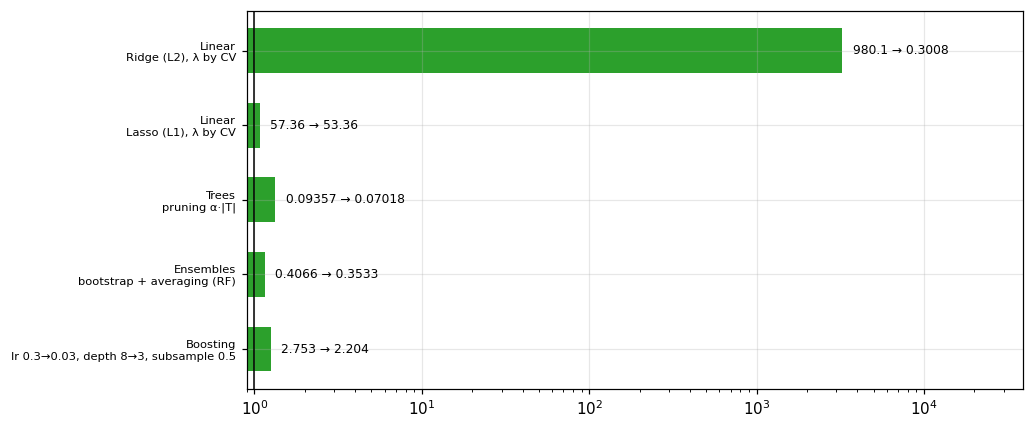

In [11]:
rows = []

X1, y1 = make_sine_data(12, seed=RS)
X1t, y1t = make_sine_data(400, seed=RS + 1)
lsm_1 = make_pipeline(PolynomialFeatures(15), LinearRegression()).fit(X1, y1)
rcv = make_pipeline(PolynomialFeatures(15), StandardScaler(),
                    RidgeCV(alphas=np.logspace(-10, 4, 100))).fit(X1, y1)
rows.append(("Linear", "poly 15 degree, 12 points", "Ridge (L2), λ by CV",
             rmse(y1t, lsm_1.predict(X1t)), rmse(y1t, rcv.predict(X1t))))

d = load_diabetes()
Xp = StandardScaler().fit_transform(PolynomialFeatures(2, include_bias=False).fit_transform(d.data))
Xp_tr, Xp_te, yp_tr, yp_te = train_test_split(Xp, d.target, test_size=0.3, random_state=RS)
lin = LinearRegression().fit(Xp_tr, yp_tr)
las = LassoCV(alphas=np.logspace(-3, 2, 80), cv=5, random_state=RS, max_iter=50000).fit(Xp_tr, yp_tr)
rows.append(("Linear", "diabetes + poly 2 degree", "Lasso (L1), λ by CV",
             rmse(yp_te, lin.predict(Xp_te)), rmse(yp_te, las.predict(Xp_te))))

rows.append(("Trees", "breast_cancer + 30 noise feat.", "pruning α·|T|",
             1 - full["test acc"], 1 - pruned["test acc"]))

X4, y4 = make_sine_data(60, noise=0.3, seed=7)
X4t, y4t = make_sine_data(400, noise=0.3, seed=8)
one = DecisionTreeRegressor(random_state=RS).fit(X4, y4)
frs = RandomForestRegressor(n_estimators=300, random_state=RS).fit(X4, y4)
rows.append(("Ensembles", "sin(2πx), 60 points", "bootstrap + averaging (RF)",
             rmse(y4t, one.predict(X4t)), rmse(y4t, frs.predict(X4t))))

Xb5, yb5 = make_friedman1(n_samples=1500, n_features=10, noise=2.0, random_state=RS)
X5tr, X5te, y5tr, y5te = train_test_split(Xb5, yb5, test_size=0.35, random_state=RS)
raw = GradientBoostingRegressor(n_estimators=700, learning_rate=0.3, max_depth=8,
                                random_state=RS).fit(X5tr, y5tr)
reg = GradientBoostingRegressor(n_estimators=700, learning_rate=0.03, max_depth=3,
                                subsample=0.5, random_state=RS).fit(X5tr, y5tr)
rows.append(("Boosting", "friedman1", "lr 0.3→0.03, depth 8→3, subsample 0.5",
             rmse(y5te, raw.predict(X5te)), rmse(y5te, reg.predict(X5te))))


summary = pd.DataFrame(rows, columns=["Family", "Task", "Mechanism", "No reg.", "With reg."])
summary["Gain, %"] = 100 * (summary["No reg."] - summary["With reg."]) / summary["No reg."]
summary["Ratio"] = summary["No reg."] / summary["With reg."]
print(summary.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(9.5, 4.0))
pos = np.arange(len(summary))
ax.barh(pos, summary["Ratio"], color="#2ca02c", height=0.6)
ax.axvline(1.0, color="k", lw=1.0)
for p, (_, r) in zip(pos, summary.iterrows()):
    ax.text(r["Ratio"] * 1.15, p, "{:.4g} → {:.4g}".format(r["No reg."], r["With reg."]),
            va="center", fontsize=8)
ax.set_yticks(pos)
ax.set_yticklabels([f + "\n" + m for f, m in zip(summary["Family"], summary["Mechanism"])],
                   fontsize=7.5)
ax.invert_yaxis()
ax.set_xscale("log")
ax.set_xlim(0.9, summary["Ratio"].max() * 12)
fig.tight_layout()
plt.show()